In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

In [22]:
df = pd.read_csv('../CSVs/arbol_edad.csv')

In [23]:
# Variable de entrada 
x = df.iloc[0:10,0].values
# Variable objetivo
y = df.iloc[0:10,1].values

print(f'x: {x}')
print(f'y: {y}')

x: [ 2.5  4.   6.   8.   9.   9.5 12.5 15.2]
y: [15 24 32 56 49 76 90 89]


In [24]:
# Inicializar los escaladores
mms_x = MinMaxScaler()
mms_y = MinMaxScaler()

# Ajustar y transformar los datos
x_train = mms_x.fit_transform(x.reshape(-1,1))
y_train = mms_y.fit_transform(y.reshape(-1,1))

print(x_train)
print(y_train)

[[0.        ]
 [0.11811024]
 [0.27559055]
 [0.43307087]
 [0.51181102]
 [0.5511811 ]
 [0.78740157]
 [1.        ]]
[[0.        ]
 [0.12      ]
 [0.22666667]
 [0.54666667]
 [0.45333333]
 [0.81333333]
 [1.        ]
 [0.98666667]]


In [25]:
m = x_train.shape[0]
print(f'm: {m}')

m: 8


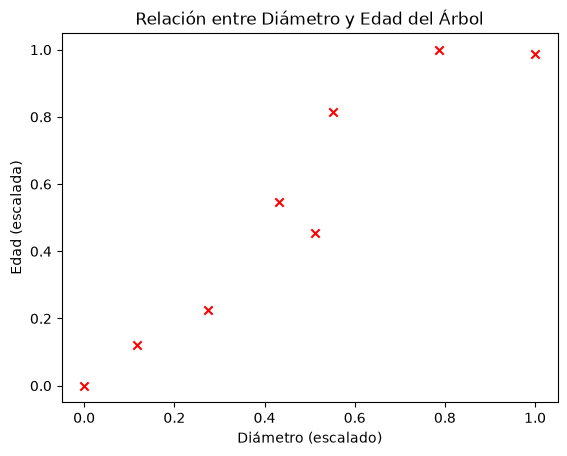

In [26]:
plt.scatter(x_train, y_train, color='red', marker='x')
plt.title('Relación entre Diámetro y Edad del Árbol')
plt.xlabel('Diámetro (escalado)')
plt.ylabel('Edad (escalada)')
plt.show()

In [27]:
def compute_cost(x, y, w, b):
    """
    Calcula la función de costo (error cuadrático medio) de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos de entrada, m ejemplos.
        y (ndarray (m,)): Valores objetivo.
        w,b (scalar): Parámetros del modelo.
    Returns:
        costo (float): J(w,b) = (1/2m) * Σ (f_wb(x_i) - y_i)^2
    """
    m = x.shape[0]
    f_wb = w * x + b
    return np.sum((f_wb - y) ** 2) / (2 * m)

w = 0.6, b = +0.4 -> costo = 0.0311
w = 1.0, b = -0.1 -> costo = 0.0192
w = 0.8, b = +0.1 -> costo = 0.0120
w = 1.1, b = +0.0 -> costo = 0.0060


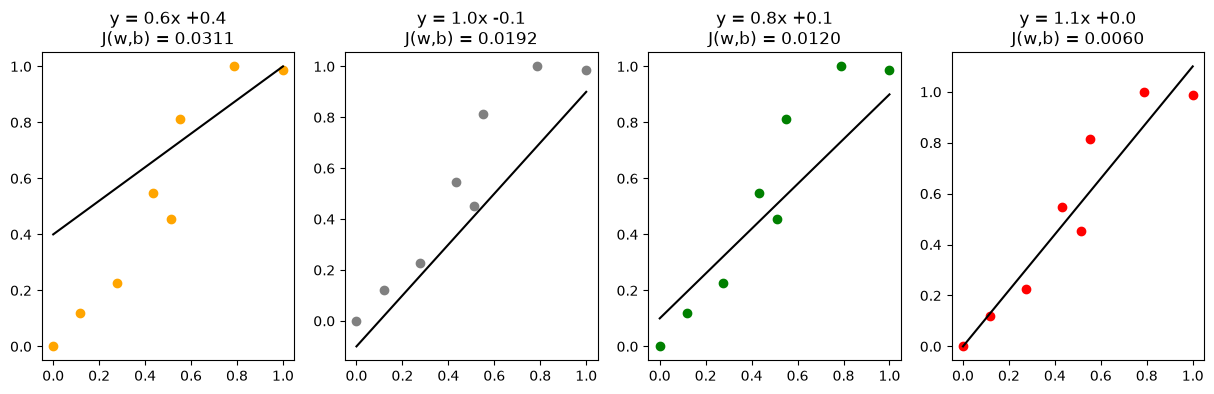

In [28]:
# Ecuaciones candidatas (w, b), de mayor a menor costo
candidatos = [(0.6, 0.4), (1.0, -0.1), (0.8, 0.1), (1.1, 0.0)]
colores = ['orange', 'gray', 'green', 'red']

fig, axs = plt.subplots(1,4, figsize=(15,4))

for ax, (w_c, b_c), color in zip(axs, candidatos, colores):
    y_p = w_c * x_train + b_c
    costo = compute_cost(x_train, y_train, w_c, b_c)
    ax.scatter(x_train, y_train, color=color)
    ax.plot(x_train, y_p, color='black')
    ax.set_title(f'y = {w_c}x {b_c:+}\nJ(w,b) = {costo:.4f}')
    print(f'w = {w_c}, b = {b_c:+} -> costo = {costo:.4f}')

plt.show()

In [29]:
def compute_model_output(x, w, b):
    """
    Calcula la predicción de un modelo lineal.

    Args:
        x (ndarray (m,)): Datos, m ejemplos.
        w,b (scalar): Parámetros del modelo.
    Returns:
        f_wb (ndarray (m,)): Predicciones del modelo.
    """
    return w * x +b

In [30]:
# Valores óptimos (menor costo entre los candidatos)
w = 1.1
b = 0.0
f_wb = compute_model_output(x_train, w, b)
print(f'Costo con w={w}, b={b}: {compute_cost(x_train, y_train, w, b):.4f}')

Costo con w=1.1, b=0.0: 0.0060


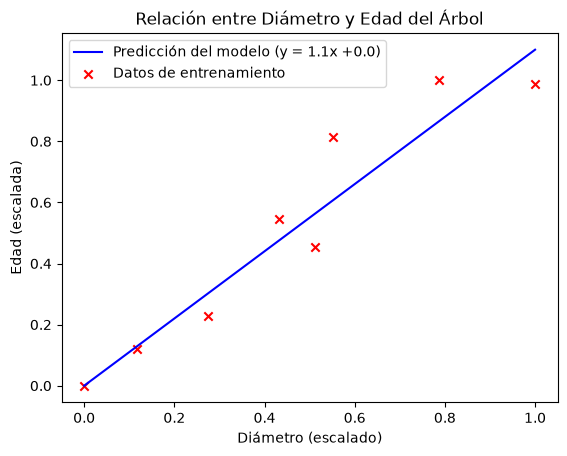

In [31]:
plt.plot(x_train, f_wb, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.scatter(x_train, y_train, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Diámetro y Edad del Árbol')
plt.xlabel('Diámetro (escalado)')
plt.ylabel('Edad (escalada)')
plt.legend()
plt.show()

In [32]:
x_i_1 = 18
diametro_escalado_1 = mms_x.transform(np.array([[x_i_1]]))
print(f'Diámetro escalado: {diametro_escalado_1}')

prediccion_1 = compute_model_output(diametro_escalado_1, w, b)
print(f'Predicción (escalada): {prediccion_1}')

edad_1 = mms_y.inverse_transform(prediccion_1)
print(f'Predicción: {edad_1[0,0]:.0f} años para un diámetro de {x_i_1} pulgadas')

Diámetro escalado: [[1.22047244]]
Predicción (escalada): [[1.34251969]]
Predicción: 116 años para un diámetro de 18 pulgadas


In [33]:
x_i_2 = 10
diametro_escalado_2 = mms_x.transform(np.array([[x_i_2]]))
print(f'Diámetro escalado: {diametro_escalado_2}')

prediccion_2 = compute_model_output(diametro_escalado_2, w, b)
print(f'Predicción (escalada): {prediccion_2}')

edad_2 = mms_y.inverse_transform(prediccion_2)
print(f'Predicción: {edad_2[0,0]:.0f} años para un diámetro de {x_i_2} pulgadas')

Diámetro escalado: [[0.59055118]]
Predicción (escalada): [[0.6496063]]
Predicción: 64 años para un diámetro de 10 pulgadas


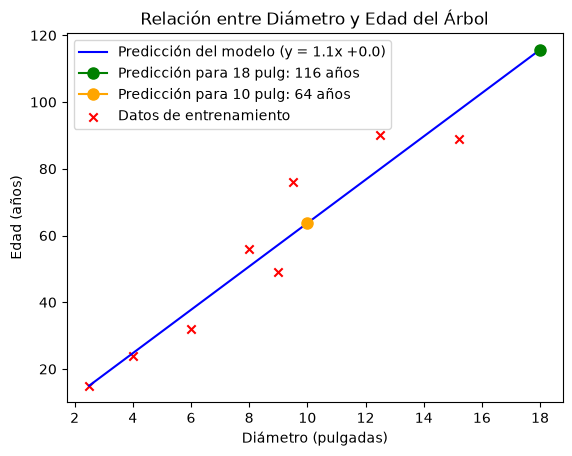

In [34]:
# Graficar en unidades reales (diámetro y edad), deshaciendo el escalado
x_real = mms_x.inverse_transform(x_train)
y_real = mms_y.inverse_transform(y_train)

# Recta del modelo desde el diámetro mínimo hasta el máximo (incluyendo las predicciones)
x_min = min(x.min(), x_i_1, x_i_2)
x_max = max(x.max(), x_i_1, x_i_2)
x_linea = np.linspace(x_min, x_max, 100).reshape(-1,1)
y_linea = mms_y.inverse_transform(compute_model_output(mms_x.transform(x_linea), w, b))

plt.plot(x_linea, y_linea, color='blue', label=f'Predicción del modelo (y = {w}x {b:+})')
plt.plot(x_i_1, edad_1[0,0], color='green', marker='o', markersize=8, label=f'Predicción para {x_i_1} pulg: {edad_1[0,0]:.0f} años')
plt.plot(x_i_2, edad_2[0,0], color='orange', marker='o', markersize=8, label=f'Predicción para {x_i_2} pulg: {edad_2[0,0]:.0f} años')
plt.scatter(x_real, y_real, color='red', marker='x', label='Datos de entrenamiento')
plt.title('Relación entre Diámetro y Edad del Árbol')
plt.xlabel('Diámetro (pulgadas)')
plt.ylabel('Edad (años)')
plt.legend()
plt.show()